# Does Binoculars still catch 2026 AI text?

A hands-on check of an AI-text detector against current models. This notebook goes with my Substack post *"I tested a top AI detector on 2026 models. Here's how much it missed."*

## What this tests
[Binoculars](https://github.com/ahans30/Binoculars) (Hans et al., ICML 2024) [1] reports detecting over 90% of AI text at a 0.01% false-flag rate. [RAID](https://raid-bench.xyz) (Dugan et al., ACL 2024) [2] is a large benchmark of human and AI text. This notebook asks one question: **do Binoculars' results still hold on text from 2026 models that neither the paper nor the benchmark has seen?**

Four groups, scored by the same detector at the same threshold:

| Group | What | n | Metric |
|---|---|---|---|
| 1 | Human texts from RAID (news + reviews) | 200 | % wrongly flagged as AI |
| 2 | Older AI texts from RAID (GPT-4 [5], Mistral-7B-Instruct [6]), written from the same sources as Group 1 | 200 | % caught |
| 3 | New texts from gpt-6-luna and Mistral Large 4, using Group 2's exact prompts | 199 | % caught |
| 4 | 100 Group 3 texts, each paraphrased by the *other* 2026 model | 100 | % caught |

## Summary of findings
At the paper's strict "low-fpr" threshold:
- **Older AI caught: 76.5%.** Mistral-7B-Instruct 99%, GPT-4 54%.
- **2026 AI caught: 19.6%.** Mistral Large 4 12%, gpt-6-luna 27%.
- **Paraphrased 2026 AI caught: 6%.** None of the 50 Mistral texts rewritten by GPT were caught.
- **Human text wrongly flagged: 0.5%** (1 of 200). 200 texts can't confirm or refute the paper's 0.01%. The 95% range is 0.1% to 2.8%.
- **Caveat:** gpt-6-luna wrote much shorter texts than GPT-4. Compared at an equal 120 words, GPT's drop mostly disappears (26% vs 21%). Mistral's drop holds (97% vs 8%).

## How to run it
**Kaggle settings:** Internet **On**. Accelerator **GPU T4 x2** only if Step 6 has texts left to score. Otherwise **None** is fine.

Each step looks for its saved output first, and only does the work if the file is missing:

| You have... | What happens | Needs |
|---|---|---|
| **The saved CSVs** (fastest; reproduces my results) | Add the published Dataset as notebook input, set the `FOLDER_PATH` secret to its folder, then Run All. Every step copies its saved file and skips its work: no RAID download, no API calls, no GPU. | A few minutes, CPU only |
| **Nothing saved** (full rerun) | Downloads RAID (~800MB), builds the sample, generates new texts through the APIs, and scores everything with Binoculars. | `OPENAI_API_KEY` and `MISTRAL_API_KEY` in Kaggle Secrets (Add-ons → Secrets), GPU T4 x2, about 2 hours of GPU time, and a few dollars of API credit |

You can mix the two. For example, keep my generated texts (Steps 3–5) but rescore them yourself by leaving out the scores file.

**Outputs** (all in `/kaggle/working`): `raid_grouped_dataset.csv` (Groups 1–2), `raid_new_generations.csv` (Group 3), `raid_paraphrased_versions.csv` (Group 4), `binoculars_scores.csv`, `text_groups.csv` (exactly what was scored), `score_analysis.csv` (all results tables), `post1_chart.png` and `score_distribution.png`.

**Never paste an API key into a cell.** Use Kaggle Secrets.

Full references are in the last cell. If you use this notebook, please cite the Binoculars [1] and RAID [2] papers.

## Step 0: Setup
Installs everything and prints the versions used, so any run can be compared with mine.

- Binoculars is installed from the official repo with `--no-deps`, because its pinned requirements are years old.
- `transformers` is pinned to **4.57.6**. Version 5 removed a function (`get_head_mask`) that Falcon's model code still calls, so Binoculars crashes on it.
- The red pip warning about `gradio` and `diffusers` is harmless. Those are Kaggle packages this notebook never uses.

**My run:** Python 3.13, torch 2.11 (CUDA 12.8), transformers 4.57.6, mistralai 3.6.0, openai 2.54.0.

In [1]:
# Clones the binoculars repository
![ -d Binoculars ] || git clone -q https://github.com/ahans30/Binoculars.git
# Installs binoculars without its old pinned requirements
!pip install -q --no-deps ./Binoculars
# Binoculars breaks on transformers 5 (get_head_mask)
!pip install -q "transformers==4.57.6"
# API SDKs for Steps 4-5
!pip install -q mistralai openai

import os, re, sys, time, math, shutil
import pandas as pd
import torch, transformers
from importlib.metadata import version

print(sys.version)
print("torch", torch.__version__, "| transformers", transformers.__version__)
print("mistralai", version("mistralai"), "| openai", version("openai"))
print("GPUs:", torch.cuda.device_count())

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
diffusers 0.42.0 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
torch 2.11.0+cu130 | transformers 4.57.6
mistralai 3.7.0 | openai 2.54.0
GPUs: 2


## Step 1: Config
Every setting lives here, so the whole experiment can be read (and changed) in one place.

- **Domains: `news` and `reviews`.** News matches what the Binoculars paper tested on, so it's a fair test of their claim. Reviews are user-written content, the kind a data team actually ingests.
- **Sample sizes:** 100 per domain per group, and 100 paraphrases.
- **Saved files:** the `SAVED` table maps each saved Dataset file to its working copy. If the saved file exists, it's copied in and the matching step skips its work. The printout shows `saved` or `build` for each file.
- **`append_row()`** adds rows one at a time and lines each one up with the file's columns. That's what makes Steps 4–6 safe to stop and resume.
- **Cleanup rules:** `clean()` removes a chatty first line ("Sure! Here's…") and a markdown title from AI text. `clean_for_scoring()` also strips markdown `*`. Human text is never changed.

In [2]:
SEED = 42
DOMAINS = ["news", "reviews"]
N_PER_DOMAIN = 100
N_NEW = 100
N_PARAPHRASE = 100

# 2024 RAID models selected
OLD_MODELS = ["gpt4", "mistral-chat"]
DECODING = "sampling"
REPETITION_PENALTY = "no"

WORK = "/kaggle/working"
RAID_PATH = "/tmp/train_none.csv"   # full RAID file, only downloaded if Step 3 has to run

# Where the saved Kaggle Datasets live. Anyone without the secret gets a path with
# nothing in it, so every step builds its own file instead.
try:
    from kaggle_secrets import UserSecretsClient
    FOLDER_PATH = UserSecretsClient().get_secret("FOLDER_PATH")
except Exception:
    FOLDER_PATH = "/kaggle/input/no-saved-datasets"

SAVED = {   # saved Dataset file -> working copy that every step reads and writes
    f"{FOLDER_PATH}/raid-step-3/raid_grouped_dataset.csv":      f"{WORK}/raid_grouped_dataset.csv",
    f"{FOLDER_PATH}/raid-step-4/raid_new_generations.csv":      f"{WORK}/raid_new_generations.csv",
    f"{FOLDER_PATH}/raid-step-5/raid_paraphrased_versions.csv": f"{WORK}/raid_paraphrased_versions.csv",
    f"{FOLDER_PATH}/raid-step-6a/binocular_scores.csv":        f"{WORK}/binoculars_scores.csv",
    f"{FOLDER_PATH}/raid-step-6b/text_groups.csv":              f"{WORK}/text_groups.csv",
    f"{FOLDER_PATH}/raid-step-7/score_analysis.csv":            f"{WORK}/score_analysis.csv",
}
SAMPLE_PATH, G3_PATH, G4_PATH, SCORES_PATH, TEXTS_PATH, ANALYSIS_PATH = SAVED.values()

# /kaggle/input is read-only, so it copies each saved file into {WORK} once.
# Steps 4-6 then add to the copy and skip anything already in it.
for saved, work in SAVED.items():
    if not os.path.exists(work) and os.path.exists(saved):
        shutil.copy(saved, work)
    print("saved" if os.path.exists(work) else "build", "->", os.path.basename(work))

# Used to download the initial raid benchmark dataset if it was not copied from a dataset
HAVE_SAMPLE = os.path.exists(SAMPLE_PATH)
if not HAVE_SAMPLE and not os.path.exists(RAID_PATH):
    !wget -q https://dataset.raid-bench.xyz/train_none.csv -O {RAID_PATH}


def append_row(path, row):
    """Add one row to a CSV. If the file exists, line the row up with its header first
    (missing columns -> blank, extra columns dropped) so values can never shift columns."""
    df = pd.DataFrame([row])
    if os.path.exists(path):
        df = df.reindex(columns=pd.read_csv(path, nrows=0).columns)
    df.to_csv(path, mode="a", header=not os.path.exists(path), index=False)


# --- Cleanup rules ---
CHATTY_OPENING = re.compile(
    r"^\s*(sure|certainly|of course|absolutely|here('|’)s|here is)\b[^\n]*\n+", re.IGNORECASE
)
TITLE_LINE = re.compile(r"^\s*(#+ .*|\*\*[^\n]+\*\*)\s*\n+")

def clean(text):
    """Used in Steps 4-5: drop a "Sure! Here's ..." first line and a markdown title line."""
    text = str(text)
    text = CHATTY_OPENING.sub("", text, count=1)
    text = TITLE_LINE.sub("", text, count=1)
    return text.strip()

def clean_for_scoring(text):
    """Used in Step 6 for every AI group: clean() plus markdown * (e.g. *Yesterday*)."""
    return clean(text).replace("*", "").strip()

saved -> raid_grouped_dataset.csv
saved -> raid_new_generations.csv
saved -> raid_paraphrased_versions.csv
saved -> binoculars_scores.csv
saved -> text_groups.csv
saved -> score_analysis.csv


## Step 2: Explore RAID before filtering it
*Skipped when the saved sample exists.*

The RAID [2] training file (`train_none.csv`, ~800MB, no adversarial attacks) is explored before anything is sampled. What I found:

1. **Generator, domain and decoding:** the `model`, `domain` and `decoding` columns (plus `repetition_penalty`).
2. **Human vs AI rows:** human rows have `model == "human"`, no `prompt`, `decoding` or `repetition_penalty`, and the same value in `id`, `adv_source_id` and `source_id`.
3. **How an AI row links to its human text:** the AI row's `source_id` equals the human row's `id`.
4. **The exact prompt the old model was given:** the `prompt` column.

In [3]:
if HAVE_SAMPLE:
    print("Using the saved sample, skipping RAID exploration")
else:
    # Will inspect the columns, first 5 rows, a human row and a non human row
    df_peek = pd.read_csv(RAID_PATH, nrows=1000)
    print(df_peek.columns.tolist())
    print(df_peek.head(5))

    print(df_peek[df_peek["model"] == "human"].head(1))
    print(df_peek[df_peek["model"] != "human"].head(1))

Using the saved sample, skipping RAID exploration


## Step 3: Build Groups 1 and 2, matched by topic
*Skipped when the saved sample exists.*

Group 2 is written from the **same** human sources as Group 1 (same titles), so any gap between the groups comes from who wrote the text, not from the topic.

- **Old generators: `gpt4` and `mistral-chat`** (Mistral-7B-Instruct). Both have current successors I can call through an API, so each family can be compared old vs new.
- **Decoding: sampling** (temperature 1, top_p 1). It's closer to how chat models are normally used than greedy decoding. It also matches the 2026 models: gpt-6-luna only runs at temperature 1, and Mistral Large 4 was set to temperature 1 and top_p 1.
- **No repetition penalty**, since chat APIs don't add one by default.
- **One generation per source text**, so no human text is over-represented, then 50 per domain per model.

**Result:** 400 rows, saved as `raid_grouped_dataset.csv`: 200 human and 200 old AI (100 GPT-4 and 100 Mistral), split evenly between news and reviews. Every AI row's `source_id` matches a human row.

In [4]:
if not HAVE_SAMPLE:
    df_test = pd.read_csv(RAID_PATH)
    print(df_test[df_test["model"] == "gpt4"][["decoding", "repetition_penalty"]].value_counts())
    print(df_test[df_test["model"] == "mistral-chat"][["decoding", "repetition_penalty"]].value_counts())
    del df_test

In [5]:
if HAVE_SAMPLE:
    print("Using the saved sample, skipping the build")
else:
    df_data = pd.read_csv(RAID_PATH)

    # Filter the dataframe for all rows that are generated by gpt4 and mistral-chat models, are of the news and reviews domain, matching decoding, and matching repetition_penalty
    df_ai_old_complete = df_data[(df_data["model"].isin(OLD_MODELS)) & (df_data["domain"].isin(DOMAINS)) & (df_data["decoding"] == DECODING) & (df_data["repetition_penalty"] == REPETITION_PENALTY)]

    # This then groups the records based on the human row they were based on
    df_ai_old_grouped = df_ai_old_complete.groupby("source_id").sample(1, random_state=SEED)

    # This then groups this subset on their domain and model and randomly selects 50 rows for each domain + model combination. So 4 subgroups * 50 rows = 200 rows
    df_ai_old_final = df_ai_old_grouped.groupby(["domain", "model"]).sample(N_PER_DOMAIN // len(OLD_MODELS), random_state=SEED).copy()

    # This then finds the matching human rows that these AI rows are based on
    df_human = df_data[(df_data["id"].isin(df_ai_old_final["source_id"])) & (df_data["model"] == "human")].copy()

    # Verifies that the dataframes have rows in them and are matching in length
    assert len(df_human) > 0, "There are no records in this dataframe."
    assert len(df_human) == len(df_ai_old_final), "Dataframe lengths do not match."

    df_human["group"] = "human"
    df_ai_old_final["group"] = "ai_old"

    required_columns = ["id", "source_id", "group", "model", "decoding", "repetition_penalty", "domain", "title", "prompt", "generation"]
    # Concatenates the human and AI records together to get a final dataframe with 400 rows (200 AI generated rows and 200 human rows they are based on)
    final_df = pd.concat([df_human, df_ai_old_final])[required_columns]
    # This outputs the final file to the working directory without an index
    final_df.to_csv(SAMPLE_PATH, index=False)
    del df_data   # frees several GB of RAM before the Falcon models load

# Reads the file and confirms the group counts match (runs either way)
check = pd.read_csv(SAMPLE_PATH)
print(check[["group", "domain"]].value_counts())
print(check[["group", "model"]].value_counts())

Using the saved sample, skipping the build
group   domain 
ai_old  news       100
        reviews    100
human   news       100
        reviews    100
Name: count, dtype: int64
group   model       
human   human           200
ai_old  gpt4            100
        mistral-chat    100
Name: count, dtype: int64


## Step 4: Generate Group 3 with 2026 models
*Only rows missing from the saved file are generated. With the saved file, nothing is sent to the APIs and no keys are needed.*

Each Group 2 prompt is sent, word for word and with no system message, to the matching 2026 model: GPT-4's prompts go to **gpt-6-luna** and Mistral's go to **Mistral Large 4**.

- **Settings:** a 4,000-token budget (both are reasoning models and spend part of it thinking before they write), and temperature 1 for Mistral to match RAID. gpt-6-luna uses low reasoning effort and fixed sampling.
- **`DROP_BBC`:** RAID's news prompts ask for "the body of a BBC news article". This option removes "BBC" for the 2026 models only, because current GPT may refuse it as a request to reproduce a copyrighted article.
- **Refusals** (answers starting "Sorry", "I can't"…) are flagged and left out of scoring.
- Every answer is saved as soon as it arrives, so a crash or rate limit loses nothing.

**Result:** 200 texts, all finished cleanly. gpt-6-luna refused 1 prompt, so 199 are usable. Neither model added chatty openings. gpt-6-luna's texts are much shorter (median about 128 words, vs 353 for GPT-4 and about 330 for Mistral Large 4), which matters for the results (see the length check in Step 7).

In [6]:
# Selected 2026 versions of the RAID chat models used
OPENAI_MODEL = "gpt-6-luna"
MISTRAL_MODEL = "mistral-large-4"
MAX_TOKENS = 4000   # reasoning models spend part of this on hidden reasoning before writing

# RAID's news prompts ask for "the body of a BBC news article", which current GPT reads as
# "reproduce a copyrighted article" and refuses. With this on, " BBC" is dropped from the
# prompt for the 2026 models only. Say so in the post.
DROP_BBC = True

REFUSAL = re.compile(r"^\s*(sorry|i can[’']t|i cannot|i[’']m sorry|i am unable)", re.IGNORECASE)

# RAID sent the prompt as an *assistant* message (raid generate code: _build_prompt).
# "user" is the normal way
PROMPT_ROLE = "user"

# RAID "sampling" = temperature 1, top_p 1
RAID_SAMPLING = {"temperature": 1, "top_p": 1}

# API clients are only created the first time something actually needs generating,
# so a run that reuses saved files needs no API keys.
_clients = {}

def get_client(family):
    if family not in _clients:
        from kaggle_secrets import UserSecretsClient
        secrets = UserSecretsClient()
        if family == "openai":
            from openai import OpenAI
            _clients[family] = OpenAI(api_key=secrets.get_secret("OPENAI_API_KEY"))
        else:
            try:
                from mistralai import Mistral
            except ImportError:
                from mistralai.client import Mistral   # newer mistralai releases moved it
            _clients[family] = Mistral(api_key=secrets.get_secret("MISTRAL_API_KEY"))
    return _clients[family]

In [7]:
def prompt_for_2026(prompt):
    return prompt.replace(" BBC news article", " news article") if DROP_BBC else prompt

# Which 2026 model replaces which RAID model
FAMILY = {"gpt4": "openai", "mistral-chat": "mistral"}

In [8]:
def generate(prompt, family):
    """Send one prompt, unchanged, with no system text. Returns a dict for one CSV row."""
    if family == "openai":
        # OpenAI prompt requires a role, reasoning effort, and content for its API call
        r = get_client("openai").responses.create(
            model=OPENAI_MODEL,
            input=[{"role": PROMPT_ROLE, "content": prompt}],
            # temperature/top_p: reasoning models reject them and already sample at 1/1
            max_output_tokens=MAX_TOKENS,
            reasoning={"effort": "low"},
        )
        return {
            "raw_text": r.output_text,
            "model_reported": r.model,
            "finished_ok": r.status == "completed",
            "input_tokens": r.usage.input_tokens,
            "output_tokens": r.usage.output_tokens,
        }
    else:
        # Mistral uses chat completion and passes similar parameters as OpenAI above
        r = get_client("mistral").chat.complete(
            model=MISTRAL_MODEL,
            messages=[{"role": "user", "content": prompt}],
            max_tokens=MAX_TOKENS,
            **RAID_SAMPLING,         # Mistral's default temperature is lower than RAID's 1
        )
        content = r.choices[0].message.content
        if not isinstance(content, str):
            # Reasoning models return a list of chunks: keep the text, skip the thinking
            content = "".join(c.text for c in content if getattr(c, "type", None) == "text")
        return {
            "raw_text": content,
            "model_reported": r.model,
            "finished_ok": r.choices[0].finish_reason == "stop",
            "input_tokens": r.usage.prompt_tokens,
            "output_tokens": r.usage.completion_tokens,
        }

In [9]:
def generate_with_retry(prompt, family, tries=4):
    # Used to force a retry up to 4 times if the initial generation failed
    for attempt in range(tries):
        try:
            return generate(prompt, family)
        except Exception as e:
            wait = 2 ** (attempt + 1)
            print(f"  {family} error: {e!r}; retrying in {wait}s")
            time.sleep(wait)
    return None

In [10]:
# --- Resume-safe loop over Step 3 prompts: only rows missing from G3_PATH get generated ---
sample = pd.read_csv(SAMPLE_PATH)
group2 = sample[sample["group"] == "ai_old"]

# Set below stores all processed IDs
done = set(pd.read_csv(G3_PATH)["source_row_id"]) if os.path.exists(G3_PATH) else set()
# Set below stores all unprocessed rows
todo = group2[~group2["id"].isin(done)]
print(f"{len(done)} done, {len(todo)} to go" + ("  -> nothing to generate, skipping" if todo.empty else ""))

for i, row in enumerate(todo.itertuples(), 1):
    family = FAMILY[row.model]
    sent_prompt = prompt_for_2026(row.prompt)
    result = generate_with_retry(sent_prompt, family)
    if result is None:
        print(f"Skipped {row.id} after retries")
        continue
    out = {
        "source_row_id": row.id,          # the Step 3 row this prompt came from
        "source_id": row.source_id,       # the human text, same as Group 1
        "domain": row.domain,
        "family": family,
        "old_model": row.model,
        "prompt": row.prompt,
        "sent_prompt": sent_prompt,
        **result,
    }
    # Refused is manually set if the answer starts with common refusal keywords
    out["refused"] = bool(REFUSAL.match(str(out["raw_text"] or "")))
    # Writes the row to CSV right away
    append_row(G3_PATH, out)
    # prints a count every 10 rows processed
    if i % 10 == 0:
        print(f"{i}/{len(todo)}")

g3 = pd.read_csv(G3_PATH)
print(g3.groupby(["domain", "family"]).size())                     # Prints all rows per domain and family (should be 50 each)
print("not finished cleanly:", (~g3["finished_ok"]).sum())         # How many rows didn't finish cleanly
print("refused:", g3.groupby("family")["refused"].sum().to_dict()) # How many rows got refused
# Only finished_ok and not refused rows go on to scoring
g3_usable = g3[g3["finished_ok"] & ~g3["refused"]]
print("usable:", len(g3_usable))
print("models reported:", g3["model_reported"].value_counts().to_dict())
print("tokens in/out:", g3["input_tokens"].sum(), g3["output_tokens"].sum())

g3["text"] = g3["raw_text"].map(clean)                             # Used to clean raw text
changed = (g3["text"] != g3["raw_text"].str.strip()).sum()
print(f"clean() changed {changed} of {len(g3)} Group 3 texts")

200 done, 0 to go  -> nothing to generate, skipping
domain   family 
news     mistral    50
         openai     50
reviews  mistral    50
         openai     50
dtype: int64
not finished cleanly: 0
refused: {'mistral': 0, 'openai': 1}
usable: 199
models reported: {'gpt-6-luna': 100, 'mistral-large-4': 100}
tokens in/out: 5536 172796
clean() changed 0 of 200 Group 3 texts


## Step 5: Paraphrase → Group 4
*Only rows missing from the saved file are generated.*

100 usable Group 3 texts (25 per model per domain) are each rewritten by the **other** 2026 model: GPT text by Mistral, Mistral text by GPT. The prompt is deliberately plain, with no tricks aimed at the detector:

> Paraphrase the following text. Keep the meaning, tone and roughly the same length. Return only the paraphrased text.

**Result:** 100 paraphrases, none refused. The length ratio (paraphrase vs original) averages 0.96–0.99, so length isn't a confound here. The printed examples show genuine rewrites with the same meaning.

In [11]:
PARAPHRASE_PROMPT = (
    "Paraphrase the following text. Keep the meaning, tone and roughly the same length. "
    "Return only the paraphrased text.\n\n{text}"
)
N_PER_FAMILY = N_PARAPHRASE // 2          # 50 GPT texts + 50 Mistral texts
CROSS = {"openai": "mistral", "mistral": "openai"}   # each family rewrites the other's text

# Pick which Group 3 texts get paraphrased: usable only, balanced by family and domain
g3 = pd.read_csv(G3_PATH)
g3 = g3[g3["finished_ok"] & ~g3["refused"]].copy()
g3["text"] = g3["raw_text"].map(clean)
to_para = g3.groupby(["family", "domain"]).sample(N_PER_FAMILY // 2, random_state=SEED)
print(to_para.groupby(["family", "domain"]).size())

# This set grabs all rows that have been processed
done4 = set(pd.read_csv(G4_PATH)["source_row_id"]) if os.path.exists(G4_PATH) else set()
# This set now stores all unprocessed rows
todo4 = to_para[~to_para["source_row_id"].isin(done4)]
print(f"{len(done4)} done, {len(todo4)} to go" + ("  -> nothing to paraphrase, skipping" if todo4.empty else ""))

family   domain 
mistral  news       25
         reviews    25
openai   news       25
         reviews    25
dtype: int64
100 done, 0 to go  -> nothing to paraphrase, skipping


In [12]:
for i, row in enumerate(todo4.itertuples(), 1):
    para_family = CROSS[row.family]                        # Get the opposite model to the current one
    result = generate_with_retry(PARAPHRASE_PROMPT.format(text=row.text), para_family)  # Perform paraphrasing
    if result is None:
        print(f"Skipped {row.source_row_id} after retries")
        continue
    out = {
        "source_row_id": row.source_row_id,   # same id as the Group 3 row it came from
        "source_id": row.source_id,
        "domain": row.domain,
        "original_family": row.family,
        "family": para_family,                # who did the paraphrasing
        "original_text": row.text,
        **result,
    }
    # Refused is manually set if the answer starts with common refusal keywords
    out["refused"] = bool(REFUSAL.match(str(out["raw_text"] or "")))
    # Writes the row to CSV right away
    append_row(G4_PATH, out)
    # prints a count every 10 rows processed
    if i % 10 == 0:
        print(f"{i}/{len(todo4)}")

g4 = pd.read_csv(G4_PATH)
g4["text"] = g4["raw_text"].map(clean)                         # Cleans up the raw text
print(g4.groupby(["original_family", "family"]).size())        # Prints all rows per original family and new family
print("not finished / refused:", (~g4["finished_ok"]).sum(), g4["refused"].sum()) # Prints count of refused or not finished rows

g4["len_ratio"] = g4["text"].str.split().str.len() / g4["original_text"].str.split().str.len()  # Used to check the length of the answers in relation to the prompt since they need to be roughly the same length
print(g4.groupby("family")["len_ratio"].describe())   # aim for roughly 0.8-1.2

# Used to randomly pick 3 rows to view the paraphrased text
for r in g4.sample(3, random_state=SEED).itertuples():
    print("=" * 80, f"\n{r.original_family} -> {r.family}\n--- ORIGINAL ---\n{r.original_text[:600]}")
    print(f"--- PARAPHRASE ---\n{r.text[:600]}\n")

original_family  family 
mistral          openai     50
openai           mistral    50
dtype: int64
not finished / refused: 0 0
         count      mean       std       min       25%       50%       75%  \
family                                                                       
mistral   50.0  0.985005  0.053744  0.876289  0.949826  0.987512  1.020635   
openai    50.0  0.963805  0.038702  0.881081  0.942476  0.967238  0.988924   

              max  
family             
mistral  1.151786  
openai   1.042056  
openai -> mistral
--- ORIGINAL ---
*Yesterday* is a charming, easygoing fantasy built around a wonderfully simple question: what if one person remembered the Beatles in a world that had forgotten them? The premise gives the film plenty of opportunities for musical nostalgia, and the familiar songs are used with warmth rather than treated as a mere checklist.

Himesh Patel makes Jack sympathetic and grounded, while Lily James brings an appealing sincerity to Ellie. Their rela

## Step 6: Score everything with Binoculars
*Skipped (no model loaded, no GPU needed) when every text already has a score.*

**How Binoculars works, simply** (see [1] for the full method): two related models read the same text. Falcon-7B is the "observer" on GPU 0, and Falcon-7B-Instruct is the "performer" on GPU 1 [3]. The score compares how surprising the text is to one model with how surprising the other model *expects* it to be. **Lower score = more AI-like.** It reads only the first 512 tokens.

- **Threshold:** the "low-fpr" threshold, 0.8536, which the authors chose for a 0.01% false-flag rate [1]. Step 7 also reports their looser "accuracy" threshold, 0.9015.
- **Two versions of each text:** full length, and cut to the first 120 words. The cut version checks whether length differences explain the results.
- **One table of all 699 texts** is built from the input files and saved as `text_groups.csv`. All AI groups go through the same cleanup.
- **Resume-safe:** each score is saved as it's computed, so a rerun skips what's already done.

**My run:** 1,398 scores (699 texts × 2), about 5.5 seconds each on a Kaggle T4 x2 in bfloat16, about 2 hours in total, using 14.4 GB per GPU (so batch size 1).

In [13]:
# Safe to import without a GPU; the GPU check happens below, only if there is scoring to do.
# Binoculars picks cuda:0 / cuda:1 at import time, so this needs the GPU session when scoring.
from binoculars import Binoculars
from binoculars.detector import BINOCULARS_FPR_THRESHOLD, BINOCULARS_ACCURACY_THRESHOLD

BATCH = 1
LENGTH_CHECK = True   # also score every text cut to its first 120 words (doubles GPU time)
CUT_WORDS = 120

OLD_FAMILY = {"gpt4": "openai", "mistral-chat": "mistral"}

In [14]:
# --- One table with every text to score (rebuilt each run from the three input files) ---
sample = pd.read_csv(SAMPLE_PATH)
# Extracts RAID's human rows
human = pd.DataFrame({
    "row_id": sample.loc[sample.group == "human", "id"],
    "group": "human",
    "domain": sample.loc[sample.group == "human", "domain"],
    "family": "human",
    "text": sample.loc[sample.group == "human", "generation"].astype(str).str.strip(),
})
old = sample[sample.group == "ai_old"]
# Extracts RAID's old AI rows
ai_old = pd.DataFrame({
    "row_id": old["id"], "group": "ai_old", "domain": old["domain"],
    "family": old["model"].map(OLD_FAMILY), "text": old["generation"].map(clean_for_scoring),
})

g3 = pd.read_csv(G3_PATH)
g3 = g3[g3.finished_ok & ~g3.refused]                # Filters for only proper rows
# The Group 3 files filtered for finished and not refused rows only
ai_new = pd.DataFrame({
    "row_id": g3["source_row_id"] + "_new", "group": "ai_new", "domain": g3["domain"],
    "family": g3["family"], "text": g3["raw_text"].map(clean_for_scoring),
})

g4 = pd.read_csv(G4_PATH)
g4 = g4[g4.finished_ok & ~g4.refused]
# The Group 4 files filtered for finished and not refused rows only
ai_para = pd.DataFrame({
    "row_id": g4["source_row_id"] + "_para", "group": "ai_para", "domain": g4["domain"],
    "family": g4["original_family"],        # whose text it was before paraphrasing
    "text": g4["raw_text"].map(clean_for_scoring),
})
# Concatenate all 4 tables into a 699 row table and renumbers their index
texts = pd.concat([human, ai_old, ai_new, ai_para], ignore_index=True)
# Drops empty text
texts = texts[texts.text.str.len() > 0]
# Counts words per text for the length check later
texts["words"] = texts.text.str.split().str.len()
# Stops if there is matching ids which will cause a clash later
assert texts.row_id.is_unique, "row_id clash between groups"
print(texts.groupby(["group", "family"]).size())
texts.to_csv(TEXTS_PATH, index=False)   # exactly what was scored

# Jobs: (row_id, variant, text). "full" = whole text, "cut120" = first 120 words
jobs = [(r.row_id, "full", r.text) for r in texts.itertuples()]
if LENGTH_CHECK:
    jobs += [(r.row_id, f"cut{CUT_WORDS}", " ".join(r.text.split()[:CUT_WORDS])) for r in texts.itertuples()]

# Used to find all records that are already scored
done = set()
if os.path.exists(SCORES_PATH):
    prev = pd.read_csv(SCORES_PATH)
    done = set(zip(prev.row_id, prev.variant))
# This keeps only jobs not in done set above
jobs = [j for j in jobs if (j[0], j[1]) not in done]
print(f"{len(done)} done, {len(jobs)} to go")

group    family 
ai_new   mistral    100
         openai      99
ai_old   mistral    100
         openai     100
ai_para  mistral     50
         openai      50
human    human      200
dtype: int64
1398 done, 0 to go


In [15]:
if jobs:
    assert torch.cuda.is_available(), "Turn on GPU T4 x2 under Settings -> Accelerator"
    assert torch.cuda.device_count() >= 2, "Binoculars needs 2 GPUs: pick GPU T4 x2, not a single T4"

    bino = Binoculars()   # falcon-7b (observer, cuda:0) + falcon-7b-instruct (performer, cuda:1), bf16, low-fpr

    def score_batch(batch):
        # Function to perform the binoculars scoring
        scores = bino.compute_score([t for _, _, t in batch])
        scores = [scores] if isinstance(scores, float) else scores
        for (rid, v, _), s in zip(batch, scores):
            append_row(SCORES_PATH, {"row_id": rid, "variant": v, "score": s})

    # Time the first 10 before committing GPU hours
    t0 = time.time()
    for i in range(0, min(10, len(jobs)), BATCH):
        score_batch(jobs[i : i + BATCH])
    per_text = (time.time() - t0) / min(10, len(jobs))
    print(f"{per_text:.1f}s per text -> about {per_text * len(jobs) / 60:.0f} min for all {len(jobs)}")
    print("GPU memory peak (GB):", [round(torch.cuda.max_memory_allocated(d) / 1e9, 1) for d in range(2)])

    # Then the rest (rerun this cell after a reset: it skips what's already scored)
    for i in range(10, len(jobs), BATCH):
        score_batch(jobs[i : i + BATCH])
        if (i // BATCH) % 25 == 0:
            print(f"{i}/{len(jobs)}")
else:
    print("All scored, skipping Binoculars")

scores = pd.read_csv(SCORES_PATH).merge(texts, on="row_id")                # Used to merge the scores file row to the texts one so all details of group, family, domain, etc. can be associated with the score
scores["flagged_ai"] = scores.score < BINOCULARS_FPR_THRESHOLD             # Applies binoculars threshold to determine AI or human prediction
print(scores[scores.variant == "full"].groupby(["group", "family"]).flagged_ai.mean().round(3))

All scored, skipping Binoculars
group    family 
ai_new   mistral    0.120
         openai     0.273
ai_old   mistral    0.990
         openai     0.540
ai_para  mistral    0.000
         openai     0.120
human    human      0.005
Name: flagged_ai, dtype: float64


## Step 7: Results tables
Each table gives, per group: n, the number and % flagged as AI, and a **95% Wilson interval** [4] (the likely range, given the sample size). For humans, "% flagged" is the false-flag rate. For AI groups, it's the % caught.

There are 12 tables: 2 thresholds × 2 text versions (full / first 120 words) × 3 splits (by group / by group + model family / by group + domain). All are saved in `score_analysis.csv`, and `show()` prints any one of them.

**Key results (low-fpr threshold, full texts):**

| | Overall | Mistral | GPT |
|---|---|---|---|
| Older AI caught | 76.5% | 99% | 54% |
| 2026 AI caught | 19.6% | 12% | 27% |
| 2026 AI paraphrased, caught | 6% | 0% (rewritten by GPT) | 12% (rewritten by Mistral) |
| Human wrongly flagged | 0.5% (1/200, range 0.1–2.8%) | | |

- **Length check (first 120 words):** Mistral's drop holds (97% → 8%), but GPT's mostly disappears (26% → 21%), so gpt-6-luna's shorter texts explain much of its drop.
- **Threshold trade-off:** the looser "accuracy" threshold catches 55.8% of 2026 AI text and still flags only 1 human on full texts, but on 120-word texts it wrongly flags 10% of humans.
- **Domains:** news and reviews give similar results.

In [16]:
scores = pd.read_csv(SCORES_PATH).merge(pd.read_csv(TEXTS_PATH), on="row_id") # Used to merge the scores file row to the texts one so all details of group, family, domain, etc. can be associated with the score
 
THRESHOLDS = {"low-fpr": BINOCULARS_FPR_THRESHOLD, "accuracy": BINOCULARS_ACCURACY_THRESHOLD}   # Stores the strict low FPR and a looser accuracy
GROUP_ORDER = ["human", "ai_old", "ai_new", "ai_para"]                               # Order the groups appear in every table
 
# This function measures how sure can I be that the percentage detected is accurate regardless of record count
def wilson(k, n, z=1.96):
    """95% interval for a rate of k out of n. Unlike +/- 1.96*sqrt(p(1-p)/n),
    it still gives a sensible range when k is 0 or n (e.g. 0 false flags out of 200)."""
    if n == 0:
        return float("nan"), float("nan")
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * math.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return max(0.0, centre - half), min(1.0, centre + half)
 
 
def rate_table(df, by):
    """% flagged as AI per group. For 'human' this is the false-flag rate,
    for the AI groups it's the % caught (recall)."""
    rows = []
    for keys, g in df.groupby(by):
        keys = keys if isinstance(keys, tuple) else (keys,)
        k, n = int(g.flagged_ai.sum()), len(g)
        lo, hi = wilson(k, n)
        rows.append({**dict(zip(by, keys)), "n": n, "flagged": k,
                     "pct_flagged": 100 * k / n, "ci_low": 100 * lo, "ci_high": 100 * hi})
    out = pd.DataFrame(rows)
    out["group"] = pd.Categorical(out["group"], GROUP_ORDER, ordered=True)
    return out.sort_values(by).round(1).reset_index(drop=True)
 
# Build every table: 2 thresholds x 2 text versions x 3 splits = 12 tables
all_tables = []
for thr_name, thr in THRESHOLDS.items():
    for variant in scores.variant.unique():
        s = scores[scores.variant == variant].copy()
        s["flagged_ai"] = s.score < thr          # low score = looks like AI
        for by in (["group"], ["group", "family"], ["group", "domain"]):
            t = rate_table(s, by)
            # Label each table so we can find it later
            t.insert(0, "threshold", thr_name)
            t.insert(1, "variant", variant)
            t.insert(2, "split", "+".join(by))
            all_tables.append(t)

# Stack all 12 into one table and save it (Step 8 reads this for the chart)
results = pd.concat(all_tables, ignore_index=True)
results.to_csv(ANALYSIS_PATH, index=False)
 
def show(threshold="low-fpr", variant="full", split="group"):
    """Print one of the 12 tables. With no arguments it prints the headline table."""
    t = results.query("threshold == @threshold and variant == @variant and split == @split")
    print(f"\n=== {threshold} threshold | {variant} texts | by {split} ===")
    # Hide empty columns and the 3 label columns (the heading already shows them)
    print(t.dropna(axis=1, how="all").drop(columns=["threshold", "variant", "split"]).to_string(index=False))

In [17]:
show()
show(split="group+family")      # old vs new within each family is the fair comparison
 
# Footnotes
show(split="group+domain")
show(threshold="accuracy")
if "cut120" in results.variant.values:
    show(variant="cut120", split="group+family")   # does the GPT/Mistral length gap explain the result?

print("\nMedian score by group/family (threshold low-fpr = %.3f):" % BINOCULARS_FPR_THRESHOLD) # Find the median score of each group or family
print(scores[scores.variant == "full"].groupby(["group", "family"]).score.median().round(3))


=== low-fpr threshold | full texts | by group ===
  group   n  flagged  pct_flagged  ci_low  ci_high
  human 200        1          0.5     0.1      2.8
 ai_old 200      153         76.5    70.2     81.8
 ai_new 199       39         19.6    14.7     25.7
ai_para 100        6          6.0     2.8     12.5

=== low-fpr threshold | full texts | by group+family ===
  group   n  flagged  pct_flagged  ci_low  ci_high  family
  human 200        1          0.5     0.1      2.8   human
 ai_old 100       99         99.0    94.6     99.8 mistral
 ai_old 100       54         54.0    44.3     63.4  openai
 ai_new 100       12         12.0     7.0     19.8 mistral
 ai_new  99       27         27.3    19.5     36.8  openai
ai_para  50        0          0.0     0.0      7.1 mistral
ai_para  50        6         12.0     5.6     23.8  openai

=== low-fpr threshold | full texts | by group+domain ===
  group   n  flagged  pct_flagged  ci_low  ci_high  domain
  human 100        0          0.0     0.0      

## Step 8: The chart
One bar chart of the headline numbers: % caught for the three AI groups, plus a separate grey bar for human text wrongly flagged (set apart because it measures something different). Error bars are the 95% Wilson intervals. The title and numbers are built from `score_analysis.csv`, so they update if anything is rerun.

Saved as `post1_chart.png`.

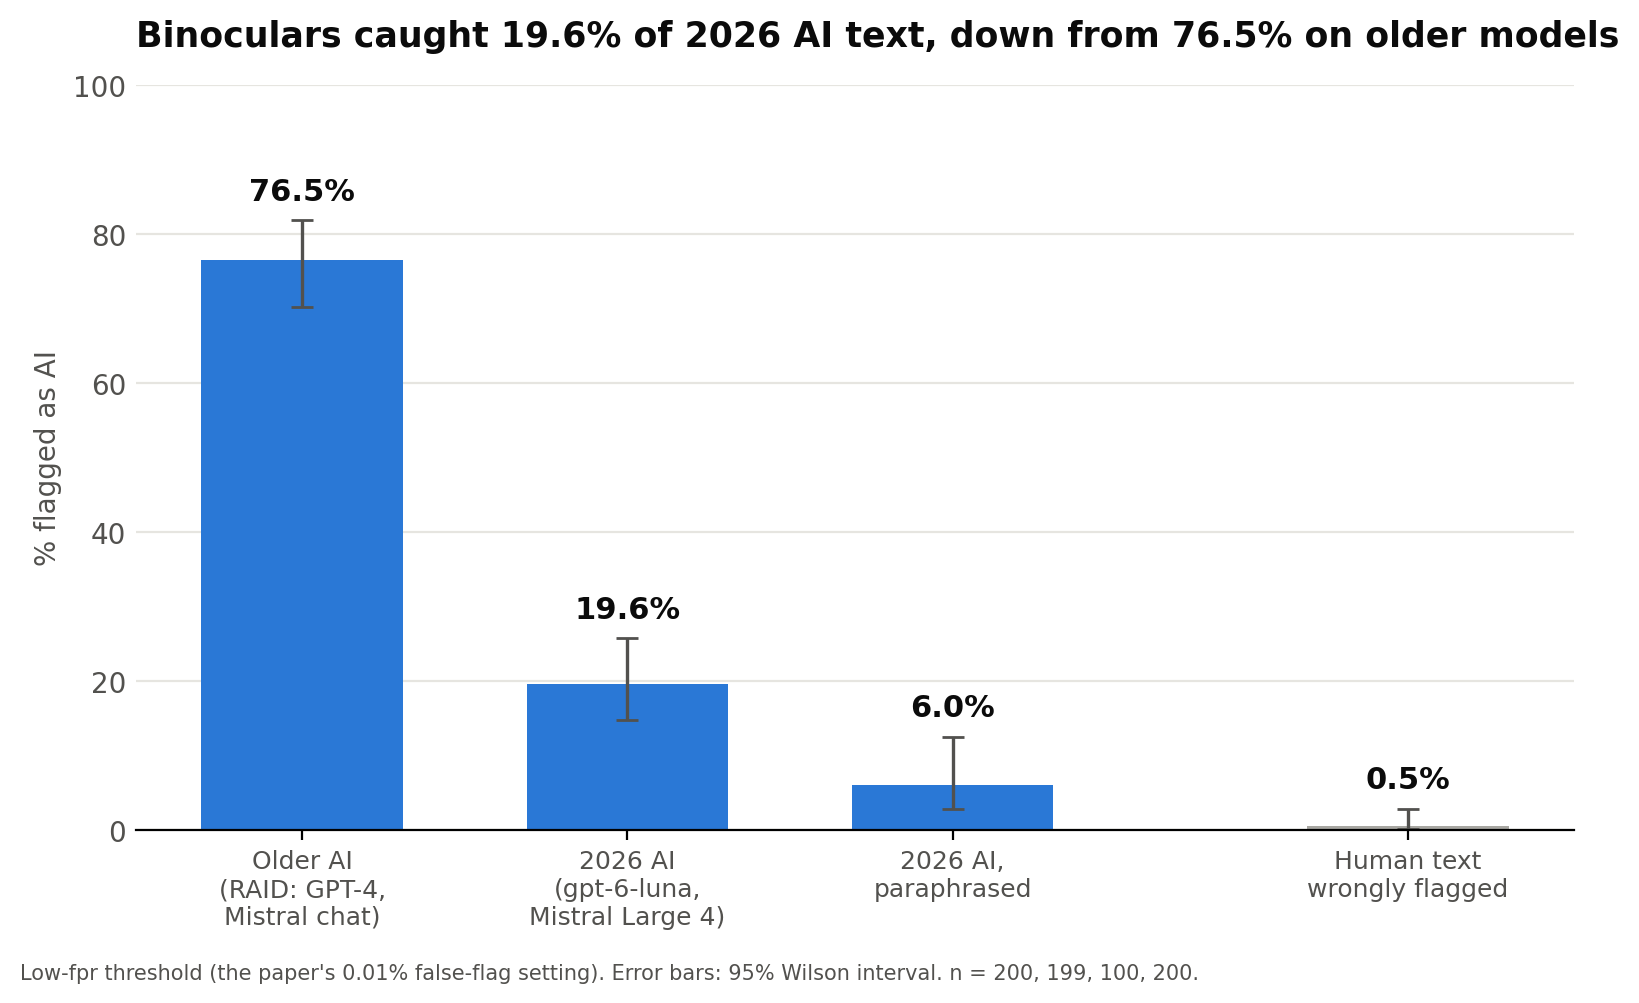

In [18]:
import matplotlib.pyplot as plt

# Headline numbers: paper's low-fpr threshold, full texts, one row per group
head = results.query("threshold == 'low-fpr' and variant == 'full' and split == 'group'").set_index("group")

# Bar order and the label under each bar
BARS = [
    ("ai_old",  "Older AI\n(RAID: GPT-4,\nMistral chat)"),
    ("ai_new",  "2026 AI\n(gpt-6-luna,\nMistral Large 4)"),
    ("ai_para", "2026 AI,\nparaphrased"),
    ("human",   "Human text\nwrongly flagged"),
]
X = [0, 1, 2, 3.4]                   # extra gap before the human bar: it measures false flags, not catches
AI_COLOR, HUMAN_COLOR = "#2a78d6", "#a8a7a2"
INK, INK_2 = "#0b0b0b", "#52514e"    # dark text, softer grey text

h = head.loc[[g for g, _ in BARS]]     # put the rows in bar order
heights, lows, highs = h.pct_flagged.values, h.ci_low.values, h.ci_high.values

fig, ax = plt.subplots(figsize=(8, 5), dpi=200)
ax.bar(X, heights, width=0.62,
       color=[AI_COLOR] * 3 + [HUMAN_COLOR],
       yerr=[heights - lows, highs - heights],      # distances from the bar, not the CI values
       error_kw={"ecolor": INK_2, "elinewidth": 1.2, "capsize": 4})

# Value label above each error bar
for x, v, hi in zip(X, heights, highs):
    ax.text(x, hi + 2, f"{v:.1f}%", ha="center", va="bottom", fontsize=11, fontweight="bold", color=INK)

# Axes: full 0-100% scale, light grid, no box lines
ax.set_xticks(X, [label for _, label in BARS], fontsize=9, color=INK_2)
ax.set_ylim(0, 100)
ax.set_ylabel("% flagged as AI", color=INK_2)
ax.yaxis.grid(True, color="#e6e5e0", linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.tick_params(axis="y", colors=INK_2, length=0)

# Title states the finding, built from the data so it stays correct
new_pct = head.loc["ai_new", "pct_flagged"]
ax.set_title(f"Binoculars caught {new_pct:.1f}% of 2026 AI text, down from "
             f"{head.loc['ai_old', 'pct_flagged']:.1f}% on older models",
             loc="left", fontsize=12.5, fontweight="bold", color=INK, pad=14)

# Footnote: threshold used, what the error bars mean, and sample sizes
fig.text(0.01, 0.01, "Low-fpr threshold (the paper's 0.01% false-flag setting). Error bars: 95% Wilson interval. "
         f"n = {', '.join(str(int(n)) for n in h.n)}.", fontsize=7.5, color=INK_2)
fig.tight_layout(rect=(0, 0.03, 1, 1))                              # leave room at the bottom for the footnote
fig.savefig(f"{WORK}/post1_chart.png", dpi=200, facecolor="white")
plt.show()


## Step 9: Look at the misses
The numbers alone can hide bugs and miss the interesting cases, so this step prints the 5 most AI-looking human texts and the 5 most human-looking 2026 AI texts. It also runs two quick bug checks and plots every group's scores against the threshold (`score_distribution.png`).

**What I found:**
- **The clearest miss** is a 48-word gpt-6-luna "news" text that says almost nothing ("the nature of the dispute… have not been specified"). Without facts to report, it wrote vague filler, and Binoculars rated it very human (score 1.11).
- **The only human text flagged** is a short, plain 71-word movie review. Short, simple writing is where the detector is weakest, in both directions.
- **The distribution plot** shows that 2026 AI scores sit almost on top of the human scores, just right of the threshold, while older AI is mostly well to its left.
- **Bug checks:** no leftover chatty openings, and only 10 of 699 texts are under 50 words.


5 most AI-looking HUMAN texts (flagged if score < 0.854)

[human | human | reviews | 71 words | score 0.847]
Kung Fu Panda 2 was not as good as the original. The story isn't as good and neither is the "Jack
Black humor" that made the original what it was. That being said, the villain is really good and the
plot is still pretty good. 2 is also a little more predictable. Overall, Kung Fu Panda 2 is a good
movie, although it fails to be as good as the first.

[human | human | news | 208 words | score 0.902]
US industrial production increased in December, according to the latest survey from the Institute
for Supply Management (ISM). Its index of national manufacturing activity rose to 58.6 last month
from 57.8 in November. A reading above 50 indicates a level of growth. The result for December was
slightly better than analysts' expectations and the 19th consecutive expansion. The ISM said the
growth was driven by a "significant" rise in the new orders. "This completes a strong year for
ma

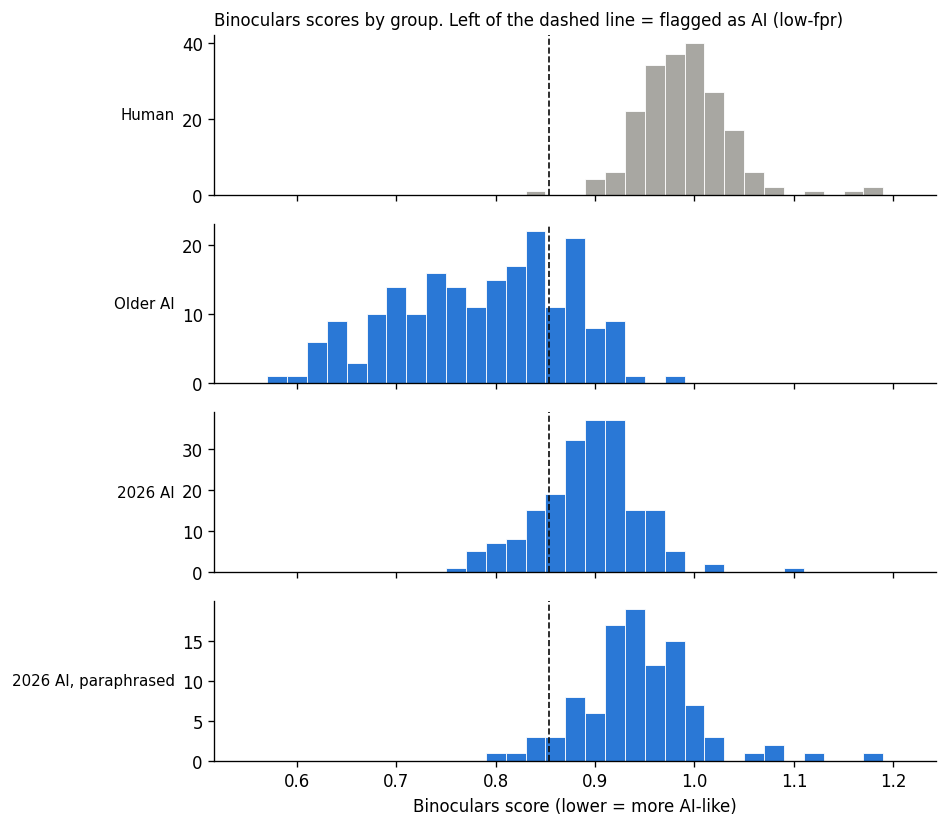

group    family 
ai_new   mistral    0.905
         openai     0.886
ai_old   mistral    0.722
         openai     0.849
ai_para  mistral    0.940
         openai     0.952
human    human      0.988
Name: score, dtype: float64


In [19]:
import textwrap
import matplotlib.pyplot as plt

full = scores[scores.variant == "full"]

def show_texts(df, title, n=5, chars=500):
    print(f"\n{'=' * 90}\n{title}\n{'=' * 90}")
    for r in df.head(n).itertuples():
        print(f"\n[{r.group} | {r.family} | {r.domain} | {r.words} words | score {r.score:.3f}]")
        print(textwrap.fill(r.text[:chars].replace("\n", " "), 100))

# Humans that looked MOST like AI (lowest scores). Anything below the threshold was wrongly flagged.
show_texts(full[full.group == "human"].sort_values("score"),
           f"5 most AI-looking HUMAN texts (flagged if score < {BINOCULARS_FPR_THRESHOLD:.3f})")

# 2026 AI texts that looked MOST human (highest scores): the clearest misses
show_texts(full[full.group == "ai_new"].sort_values("score", ascending=False),
           "5 most human-looking 2026 AI texts (the clearest misses)")

# Sanity checks for bugs that would skew the scores
print("\nAny leftover chatty openings in AI text:",
      full[full.group != "human"].text.str.match(r"\s*(sure|certainly|here('|’)s|here is)\b", case=False).sum())
print("Texts under 50 words per group:", full[full.words < 50].groupby("group").size().to_dict())

# Score distribution per group with the threshold line
GROUPS = [("human", "Human"), ("ai_old", "Older AI"), ("ai_new", "2026 AI"), ("ai_para", "2026 AI, paraphrased")]
fig, axes = plt.subplots(len(GROUPS), 1, figsize=(8, 7), sharex=True, dpi=120)
bins = [x / 100 for x in range(55, 122, 2)]
for ax, (g, label) in zip(axes, GROUPS):
    ax.hist(full.loc[full.group == g, "score"], bins=bins,
            color="#a8a7a2" if g == "human" else "#2a78d6", edgecolor="white", linewidth=0.5)
    ax.axvline(BINOCULARS_FPR_THRESHOLD, color="#0b0b0b", linestyle="--", linewidth=1)
    ax.set_ylabel(label, rotation=0, ha="right", va="center", fontsize=9)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
axes[0].set_title("Binoculars scores by group. Left of the dashed line = flagged as AI (low-fpr)", loc="left", fontsize=10)
axes[-1].set_xlabel("Binoculars score (lower = more AI-like)")
fig.tight_layout()
fig.savefig(f"{WORK}/score_distribution.png", dpi=150, facecolor="white")
plt.show()

# Median score per group/family: how far each sits from the threshold
print(full.groupby(["group", "family"]).score.median().round(3))


## Step 10: Limitations
- **Sample size:** 200 human, 200 older AI, 199 new AI and 100 paraphrased texts. That's enough to show large drops, but not to test a 0.01% false-flag rate, which would need tens of thousands of human texts.
- **Domains:** news and reviews only.
- **Models:** one older and one 2026 model per family: GPT-4 → gpt-6-luna and Mistral-7B-Instruct → Mistral Large 4, called through their APIs in October 2026. Results may change as the models are updated.
- **Length confound:** gpt-6-luna wrote much shorter texts. The 120-word check shows this explains much of GPT's drop, but not Mistral's.
- **Setup:** the official Binoculars code, run on transformers 4.57.6 (the repo pins 4.31.0) in bfloat16 on T4 GPUs. The thresholds were chosen at bfloat16, and the T4 has no native bfloat16 support.
- **Prompts:** RAID's original prompts, sent as a user message with no system message. RAID itself sent OpenAI prompts as an assistant message. The `DROP_BBC` setting changes the news prompts for the 2026 models only.
- **Cleanup:** AI text has a chatty first line, a markdown title and `*` removed. In practice no openings or titles needed removing; only markdown `*` was stripped. Human text is never changed.
- **One detector** [1], at the authors' two published thresholds. Other detectors may behave differently.

**Data:** RAID [2] is used under its own licence; check it before reusing the data. The generated texts were produced through the OpenAI and Mistral APIs under their terms.

## References
1. Hans, A., Schwarzschild, A., Cherepanova, V., Kazemi, H., Saha, A., Goldblum, M., Geiping, J., & Goldstein, T. (2024). *Spotting LLMs With Binoculars: Zero-Shot Detection of Machine-Generated Text.* ICML 2024. [arXiv:2401.12070](https://arxiv.org/abs/2401.12070). Code: [github.com/ahans30/Binoculars](https://github.com/ahans30/Binoculars)
2. Dugan, L., Hwang, A., Trhlík, F., Ludan, J. M., Zhu, A., Xu, H., Ippolito, D., & Callison-Burch, C. (2024). *RAID: A Shared Benchmark for Robust Evaluation of Machine-Generated Text Detectors.* ACL 2024. [arXiv:2405.07940](https://arxiv.org/abs/2405.07940). Data: [raid-bench.xyz](https://raid-bench.xyz)
3. Almazrouei, E., et al. (2023). *The Falcon Series of Open Language Models.* [arXiv:2311.16867](https://arxiv.org/abs/2311.16867). Models: [tiiuae/falcon-7b](https://huggingface.co/tiiuae/falcon-7b), [tiiuae/falcon-7b-instruct](https://huggingface.co/tiiuae/falcon-7b-instruct)
4. Wilson, E. B. (1927). *Probable Inference, the Law of Succession, and Statistical Inference.* Journal of the American Statistical Association, 22(158), 209-212.
5. OpenAI (2023). *GPT-4 Technical Report.* [arXiv:2303.08774](https://arxiv.org/abs/2303.08774)
6. Jiang, A. Q., et al. (2023). *Mistral 7B.* [arXiv:2310.06825](https://arxiv.org/abs/2310.06825)

The 2026 models (gpt-6-luna, Mistral Large 4) were called through the OpenAI and Mistral APIs; see each provider's model documentation.